Dataset shape: (5000, 3)
sentiment
positive    2519
negative    2481
Name: count, dtype: int64

Sample reviews:
                                              review sentiment
0  I really liked this Summerslam due to the look...  positive
1  Not many television shows appeal to quite as m...  positive
2  The film quickly gets to a major chase scene w...  negative

Train shape: (4000, 5000), Test shape: (1000, 5000)

Evaluation Results:
              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression     0.848     0.8321  0.8750    0.8530
        Naive Bayes     0.835     0.8480  0.8194    0.8335


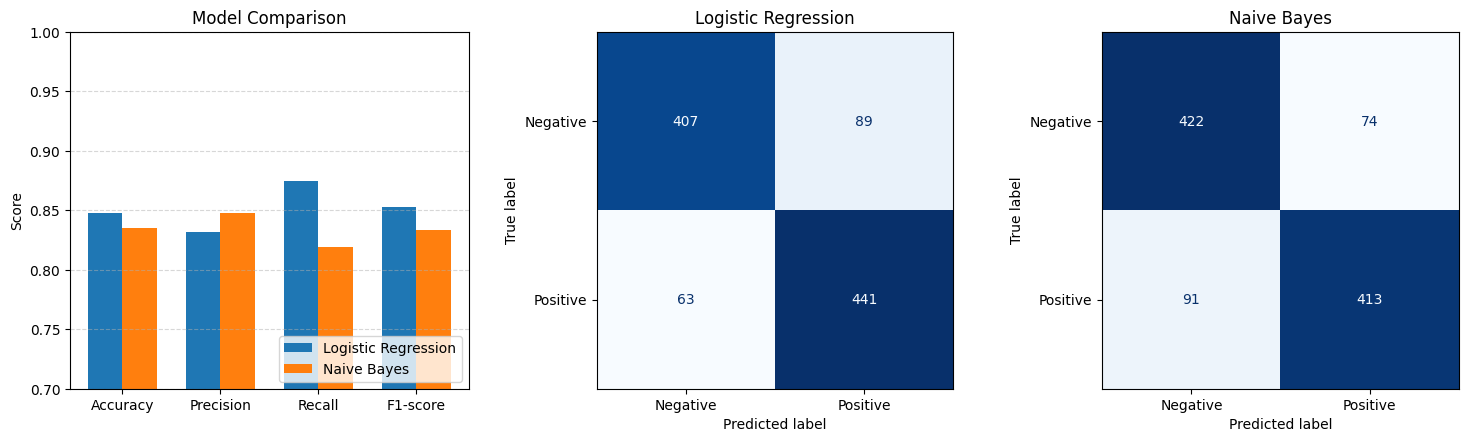


Top positive words (LogReg): great, best, excellent, amazing, fun, love, favorite, life
Top negative words (LogReg): bad, worst, awful, waste, acting, stupid, poor, boring

Custom reviews test:
                                                                     Review   Actual   LogReg NaiveBayes
                                     Amazing product! I absolutely love it. Positive Positive   Positive
                                          Terrible quality. Waste of money. Negative Negative   Negative
I expected something better from this director, the plot was disappointing. Negative Negative   Negative
         Not bad at all, I actually enjoyed the story despite a slow start. Positive Negative   Negative


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# 1. Load dataset (5,000 sample from IMDb reviews)
url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
df = pd.read_csv(url)

df = df.sample(n=5000, random_state=42).reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)

print(f"Dataset shape: {df.shape}")
print(df["sentiment"].value_counts())
print("\nSample reviews:")
print(df[["review", "sentiment"]].head(3))


# 2. Text preprocessing & TF-IDF
def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", str(text))
    text = text.lower()
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["clean_review"] = df["review"].apply(clean_text)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df["clean_review"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"],
)

tfidf = TfidfVectorizer(max_features=5000, stop_words="english")
X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")


# 3. Train and evaluate models
lr = LogisticRegression(max_iter=1000, random_state=42)
nb = MultinomialNB()

lr.fit(X_train, y_train)
nb.fit(X_train, y_train)

lr_preds = lr.predict(X_test)
nb_preds = nb.predict(X_test)

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": round(accuracy_score(y_test, lr_preds), 4),
        "Precision": round(precision_score(y_test, lr_preds), 4),
        "Recall": round(recall_score(y_test, lr_preds), 4),
        "F1-score": round(f1_score(y_test, lr_preds), 4),
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": round(accuracy_score(y_test, nb_preds), 4),
        "Precision": round(precision_score(y_test, nb_preds), 4),
        "Recall": round(recall_score(y_test, nb_preds), 4),
        "F1-score": round(f1_score(y_test, nb_preds), 4),
    },
])

print("\nEvaluation Results:")
print(results.to_string(index=False))


# 4. Plot metrics and confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metrics))
width = 0.35

axes[0].bar(x - width / 2, results.loc[0, metrics], width, label="Logistic Regression")
axes[0].bar(x + width / 2, results.loc[1, metrics], width, label="Naive Bayes")
axes[0].set_ylim(0.7, 1.0)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylabel("Score")
axes[0].set_title("Model Comparison")
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_preds),
    display_labels=["Negative", "Positive"],
).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, nb_preds),
    display_labels=["Negative", "Positive"],
).plot(ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title("Naive Bayes")

plt.tight_layout()
plt.savefig("sentiment_analysis_comparison.png", dpi=150)
plt.show()


# 5. Top words and manual error check
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr.coef_[0]

print("\nTop positive words (LogReg):", ", ".join(feature_names[np.argsort(coefs)[-8:][::-1]]))
print("Top negative words (LogReg):", ", ".join(feature_names[np.argsort(coefs)[:8]]))

custom_reviews = [
    ("Amazing product! I absolutely love it.", "Positive"),
    ("Terrible quality. Waste of money.", "Negative"),
    ("I expected something better from this director, the plot was disappointing.", "Negative"),
    ("Not bad at all, I actually enjoyed the story despite a slow start.", "Positive"),
]

check_rows = []
for text, true_label in custom_reviews:
    vec = tfidf.transform([clean_text(text)])
    check_rows.append({
        "Review": text,
        "Actual": true_label,
        "LogReg": "Positive" if lr.predict(vec)[0] == 1 else "Negative",
        "NaiveBayes": "Positive" if nb.predict(vec)[0] == 1 else "Negative",
    })

print("\nCustom reviews test:")
print(pd.DataFrame(check_rows).to_string(index=False))